In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

In [3]:
api_key = ""

def api(key):
    global api_key
    api_key = key

def params_categories(category_id):
    params = {
        'category_id': category_id,
        'api_key': api_key,
        'file_type': 'json'
    }
    return params

def params_series(series_id):
    params = {
        'series_id': series_id,
        'api_key': api_key,
        'file_type': 'json'
    }
    return params

def params_search(search_text):
    params = {
        'search_text': search_text,
        'api_key': api_key,
        'file_type': 'json'
    }
    return params
    
def get_categories(category_id):
    url = 'https://api.stlouisfed.org/fred/category/children'
    params = params_categories(category_id)
    response = requests.get(url, params=params)
    data = response.json()
    df = pd.json_normalize(data['categories'])
    return df

def get_categories_series(category_id):
    url = 'https://api.stlouisfed.org/fred/category/series'
    params = params_categories(category_id)
    response = requests.get(url, params=params)
    data = response.json()
    df = pd.json_normalize(data["seriess"])
    return df

def get_series(series_id):
    url = 'https://api.stlouisfed.org/fred/series/observations'
    params = params_series(series_id)
    response = requests.get(url, params=params)
    data = response.json()
    df = pd.json_normalize(data["observations"])
    return df

def get_search(series_text):
    url = 'https://api.stlouisfed.org/fred/series/search'
    params = params_search(series_text)
    response = requests.get(url, params=params)
    data = response.json()
    df = pd.json_normalize(data["seriess"])
    return df

def normalisasi(url):
    response = requests.get(url)
    data = response.json()
    
    if "seriess" in data:
        df = pd.json_normalize(data["seriess"])
    elif "categories" in data:
        df = pd.json_normalize(data["categories"])
    elif "observations" in data:
        df = pd.json_normalize(data["observations"])
        
    df["value"] = pd.to_numeric(df["value"], errors='coerce')
    df["date"] = pd.to_datetime(df["date"])
    return df

def makro_indonesia(*args):  
    urls = [f"https://api.stlouisfed.org/fred/series/observations?series_id={arg}&api_key=d099e8a4f1b849feb319c554d18cb172&file_type=json" for arg in args]
    dfs = [normalisasi(url) for url in urls]
    
    if len(urls) == 1:
        label = ["OIL"]
    elif len(urls) == 2:
        label = ["OIL", "Interest rate"]
    
    plt.figure(figsize=(12,6))
    for df, arg in zip(dfs, label):
        sns.lineplot(x="date", y="value", data=df, errorbar=None, label = arg)
    
    plt.grid(True)
    plt.legend()
    plt.title("Makro Indonesia")
    plt.show()
    
    

In [4]:
# API KEY

api("d099e8a4f1b849feb319c554d18cb172")

In [5]:
data = get_categories(0)
data[["id", "name"]]

,id,name
0,32991,"Money, Banking, & Finance"
1,10,"Population, Employment, & Labor Markets"
2,32992,National Accounts
3,1,Production & Business Activity
4,32455,Prices
5,32263,International Data
6,3008,U.S. Regional Data
7,33060,Academic Data


In [6]:
data = get_categories(32991)
data[["id", "name"]]

,id,name
0,22,Interest Rates
1,15,Exchange Rates
2,24,Monetary Data
3,46,Financial Indicators
4,23,Banking
5,32360,Business Lending
6,32145,Foreign Exchange Intervention


In [7]:
data = get_categories(22)
data[["id", "name"]]

,id,name
0,34009,AMERIBOR Benchmark Rates
1,33058,Automobile Loan Rates
2,51,Bankers Acceptance Rate
3,121,Certificates of Deposit
4,120,Commercial Paper
5,32348,Corporate Bonds
6,33059,Credit Card Loan Rates
7,34005,EONIA Rates
8,34007,Euro Short-Term Rate
9,32298,Eurodollar Deposits


In [8]:
data = get_categories_series(34009)
data[["id", "title"]]

,id,title
0,AMBOR1M,1-Month AMERIBOR Term Structure of Interest Rates (DISCONTINUED)
1,AMBOR1W,1-Week AMERIBOR Term Structure of Interest Rates (DISCONTINUED)
2,AMBOR1Y,1-Year AMERIBOR Term Structure of Interest Rates (DISCONTINUED)
3,AMBOR2Y,2-Year AMERIBOR Term Structure of Interest Rates (DISCONTINUED)
4,AMBOR30,30-Day Moving Average AMERIBOR Benchmark Interest Rate
5,AMBOR30T,AMERIBOR Term-30 Derived Interest Rate Index
6,AMBOR3M,3-Month AMERIBOR Term Structure of Interest Rates (DISCONTINUED)
7,AMBOR6M,6-Month AMERIBOR Term Structure of Interest Rates (DISCONTINUED)
8,AMBOR90,90-Day Moving Average AMERIBOR Benchmark Interest Rate
9,AMBOR90T,AMERIBOR Term-90 Derived Interest Rate Index


In [9]:
data = get_series("AMBOR30")
data.head()

,realtime_start,realtime_end,date,value
0,2024-08-07,2024-08-07,2019-06-19,2.4167052
1,2024-08-07,2024-08-07,2019-06-20,2.4164311
2,2024-08-07,2024-08-07,2019-06-21,2.41657031
3,2024-08-07,2024-08-07,2019-06-22,2.41663992
4,2024-08-07,2024-08-07,2019-06-23,2.41668168


In [10]:
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

In [11]:
data.dtypes

realtime_start            object
realtime_end              object
date              datetime64[ns]
value                    float64
dtype: object

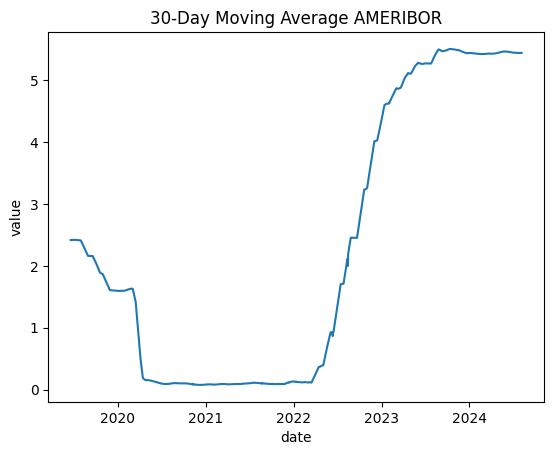

In [12]:
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.title("30-Day Moving Average AMERIBOR")
plt.show()

Exchange rate RP to USD


In [21]:
data = get_search("indonesia exchange rate")
data[["id", "title"]].head()

,id,title
0,TWEXB,"Trade Weighted U.S. Dollar Index: Broad, Goods (DISCONTINUED)"
1,CCUSSP02IDM650N,"Currency Conversions: US Dollar Exchange Rate: Spot, End of Period: National Currency: USD for Indonesia"
2,CCUSSP02IDQ650N,"Currency Conversions: US Dollar Exchange Rate: Spot, End of Period: National Currency: USD for Indonesia"
3,CCUSSP02IDA650N,"Currency Conversions: US Dollar Exchange Rate: Spot, End of Period: National Currency: USD for Indonesia"
4,DTWEXB,Nominal Broad U.S. Dollar Index (Goods Only) (DISCONTINUED)


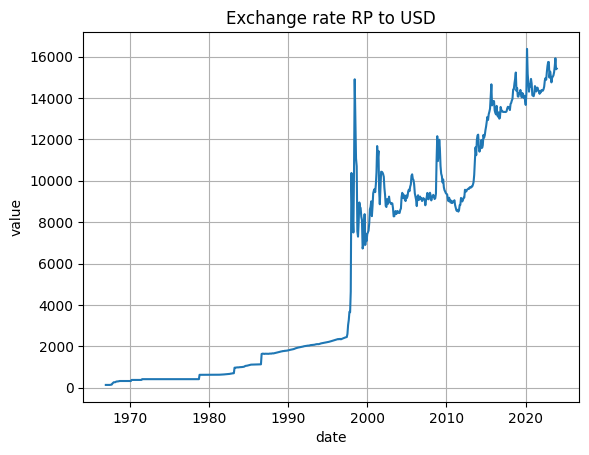

In [14]:
data = get_series("CCUSSP02IDM650N")
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Exchange rate RP to USD")
plt.show()

GDP INDONESIA


In [22]:
data = get_search("indonesia GDP")
data[["id", "title"]].head()

,id,title
0,NGDPRSAXDCIDQ,Real Gross Domestic Product for Indonesia
1,NGDPRNSAXDCIDQ,Real Gross Domestic Product for Indonesia
2,NGDPRXDCIDA,Real Gross Domestic Product for Indonesia
3,NGDPSAXDCIDQ,Nominal Gross Domestic Product for Indonesia
4,NGDPXDCIDA,Nominal Gross Domestic Product for Indonesia


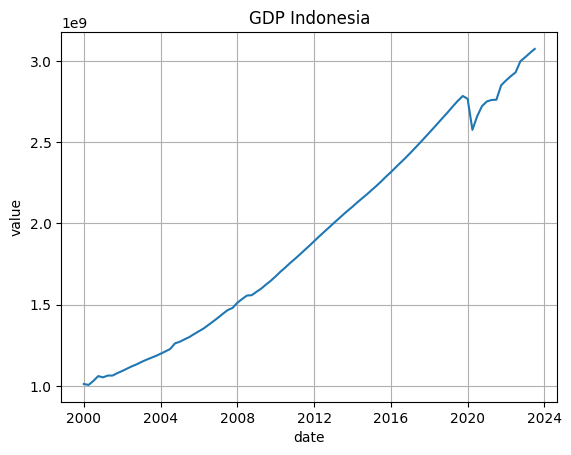

In [15]:
data = get_series("NGDPRSAXDCIDQ")
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("GDP Indonesia")
plt.show()

INFLATION


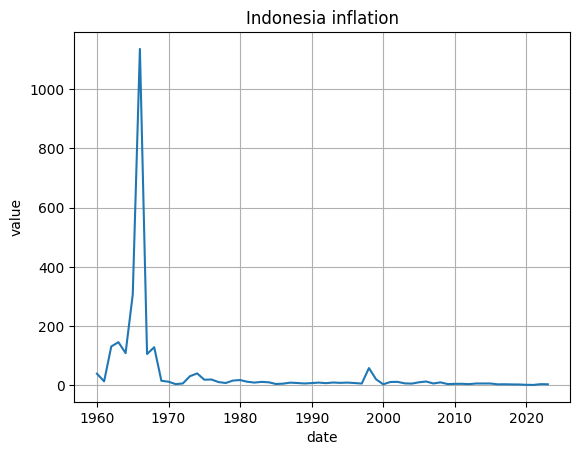

In [16]:
data = get_series("FPCPITOTLZGIDN")
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Indonesia inflation")
plt.show()

INTEREST RATE


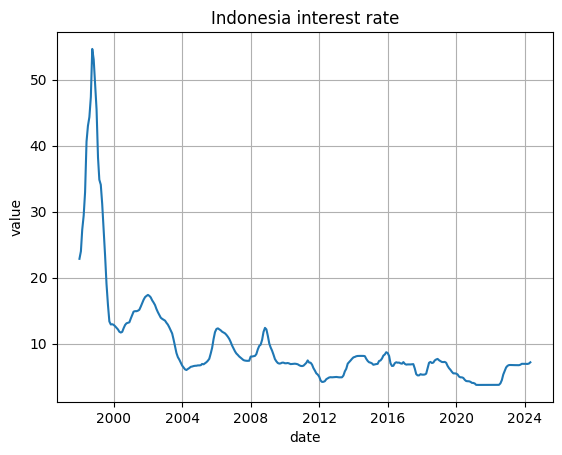

In [17]:
data = get_series("IR3TIB01IDM156N")
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Indonesia interest rate")
plt.show()

OIL


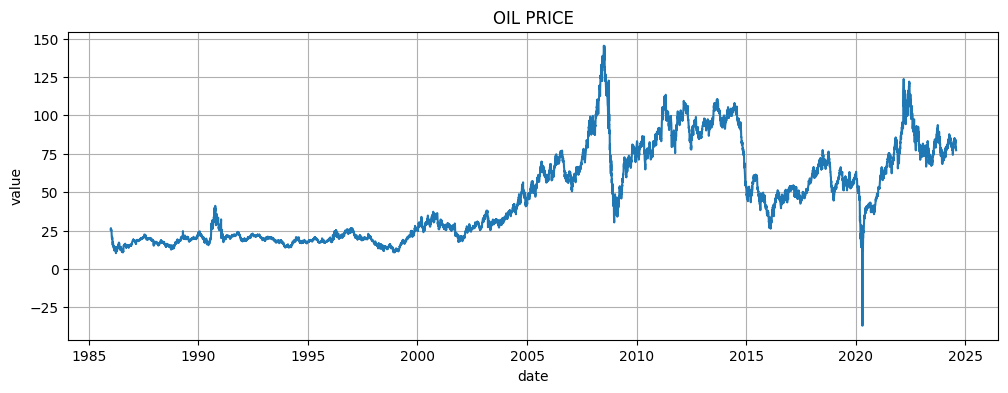

In [18]:
data = get_series("DCOILWTICO")
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

plt.figure(figsize=(12,4))
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("OIL PRICE")
plt.show()

UNEMPLOYMENT


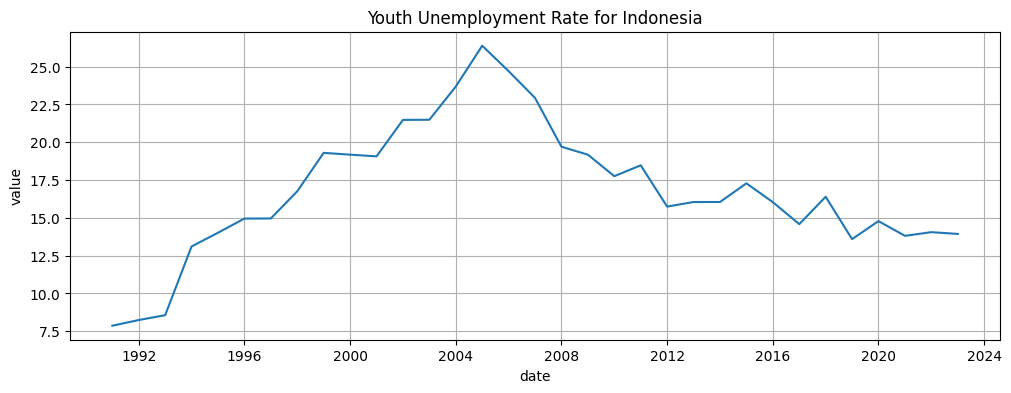

In [19]:
data = get_series("SLUEM1524ZSIDN")
data["value"] = pd.to_numeric(data["value"], errors='coerce')
data["date"] = pd.to_datetime(data["date"])

plt.figure(figsize=(12,4))
sns.lineplot(x = "date", y = "value", data = data, errorbar=None)
plt.grid(True)
plt.title("Youth Unemployment Rate for Indonesia")
plt.show()


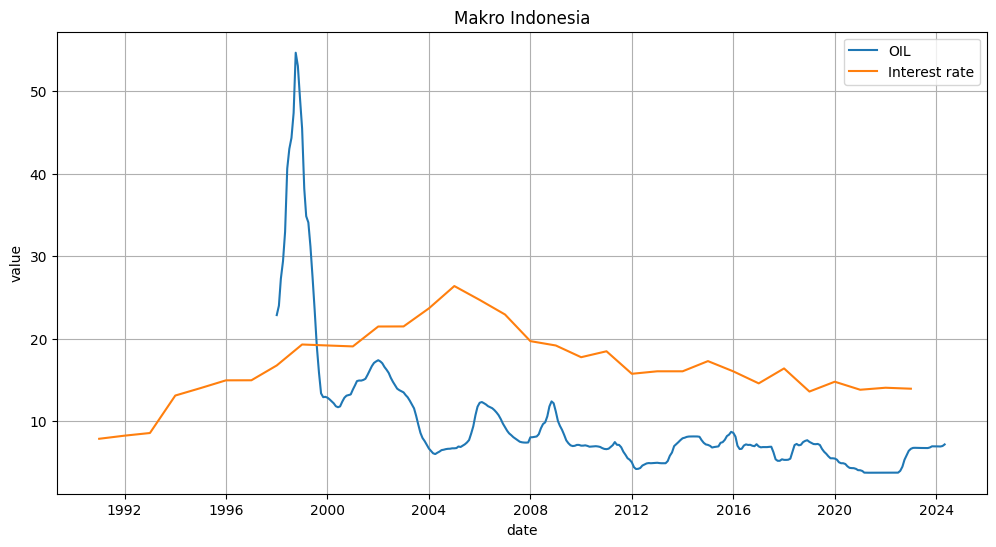

In [20]:
makro_indonesia("IR3TIB01IDM156N", "SLUEM1524ZSIDN")